# Checkpoint 2

Source: [U.S. DoE College Scorecard](https://collegescorecard.ed.gov/data/)

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Columns chosen for our questions
selected_columns = [
    "UNITID",           ## Unit ID for institution 
    "INSTNM",           ## Institution name
    "CITY",
    "STABBR",           ## State postcode
    "CONTROL",          ## Control of institution [Public, Private nonprofit, Private for-profit]
    "PREDDEG",          ## Predominant undergraduate degree awarded
    "ADM_RATE", 
    "SAT_AVG",
    "UGDS",             ## Enrollment of undergraduate certificate/degree-seeking students
    "COSTT4_A",         ## Average cost of attendance (academic year institutions)
    "TUITIONFEE_IN",    ## In-state tuition and fees
    "C150_4",           ## Completion rate for first-time, full-time students at four-year institutions (150% of expected time to completion)
    "MD_EARN_WNE_P10",  ## Median earnings of students working and not enrolled 10 years after entry
    "DEBT_MDN",         ## The median original amount of the loan principal upon entering repayment
    "PCTPELL",          ## Percentage of undergraduates who receive a Pell Grant
]

# Treat "PS" as missing when reading
scorecard = pd.read_csv(
    "data/Most-Recent-Cohorts-Institution.csv",
    usecols=selected_columns,
    na_values=["PS", "NULL", ""],
    dtype={"STABBR": "string"},
    low_memory=False,
)

text_columns = ["INSTNM", "CITY", "STABBR"]
for column in selected_columns:
    if column not in text_columns:
        scorecard[column] = pd.to_numeric(scorecard[column], errors="coerce")
        
scorecard["CONTROL_LABEL"] = scorecard["CONTROL"].map(
    {1: "Public", 2: "Private nonprofit", 3: "Private for-profit"}
)

scorecard[selected_columns].head()


,UNITID,INSTNM,CITY,STABBR,CONTROL,PREDDEG,ADM_RATE,SAT_AVG,UGDS,COSTT4_A,TUITIONFEE_IN,C150_4,MD_EARN_WNE_P10,DEBT_MDN,PCTPELL
0,100654,Alabama A & M University,Normal,AL,1,3,0.5795,938.0,6124.0,27732.0,10558.0,0.2771,41266.0,14250.0,0.6419
1,100663,University of Alabama at Birmingham,Birmingham,AL,1,3,0.8818,1258.0,11635.0,27987.0,9812.0,0.6612,59631.0,14166.0,0.3885
2,100690,Amridge University,Montgomery,AL,2,3,NaN,NaN,241.0,NaN,NaN,0.5000,40519.0,19191.0,0.4568
3,100706,University of Alabama in Huntsville,Huntsville,AL,1,3,0.6857,1319.0,6591.0,32089.0,12458.0,0.6246,72098.0,15000.0,0.2781
4,100724,Alabama State University,Montgomery,AL,1,3,0.9755,976.0,3477.0,23655.0,11248.0,0.3070,40585.0,15000.0,0.7197


In [12]:
# Share of missing values per column, largest first
missing_share = scorecard.isna().mean().sort_values(ascending=False)
print(missing_share.round(3))

SAT_AVG            0.835
ADM_RATE           0.695
C150_4             0.637
COSTT4_A           0.486
TUITIONFEE_IN      0.419
DEBT_MDN           0.173
MD_EARN_WNE_P10    0.157
UGDS               0.127
PCTPELL            0.124
CONTROL            0.000
PREDDEG            0.000
STABBR             0.000
INSTNM             0.000
UNITID             0.000
CITY               0.000
CONTROL_LABEL      0.000
dtype: float64


### Hypothesis 1: The median debt is related to the median earnings.
H0: Among bachelor’s-granting institutions (PREDDEG == 3) with both values reported, there is no monotonic association between DEBT_MDN and MD_EARN_WNE_P10 (Spearman ρ = 0).  <br>
H1: There is a monotonic association (ρ != 0).

In [13]:
bachelor = scorecard[scorecard["PREDDEG"] == 3]
complete = bachelor.dropna(subset=["DEBT_MDN", "MD_EARN_WNE_P10"])
print("Complete cases:", len(complete))

rho, p_value = stats.spearmanr(complete["DEBT_MDN"], complete["MD_EARN_WNE_P10"])
print("Overall: rho =", round(rho, 3), " p =", p_value)

Complete cases: 1745
Overall: rho = 0.37  p = 8.648113648537129e-58


The p_value is far below the typical significance level of α = 0.05, thus rejecting the null hypothesis. <br>
The correlation ρ = 0.37 indicates a moderate positive monotonic association between median debt (DEBT_MDN) and median earnings (MD_EARN_WNE_P10).

### Follow Up: Does this relation hold within each institution type?
H0: Within each control type (public, private nonprofit, for-profit), ρ = 0.

In [14]:
group_names = ["Public", "Private nonprofit", "Private for-profit"]
number_of_tests = len(group_names)

for group in group_names:
    group_data = complete[complete["CONTROL_LABEL"] == group]
    group_rho, group_p = stats.spearmanr(group_data["DEBT_MDN"], group_data["MD_EARN_WNE_P10"])
    adjusted_p = min(group_p * number_of_tests, 1)
    print(group, ": n =", len(group_data), ", rho =", round(group_rho, 3), ", adjusted p =", adjusted_p)

Public : n = 583 , rho = 0.334 , adjusted p = 3.4893074460463504e-16
Private nonprofit : n = 1034 , rho = 0.383 , adjusted p = 6.392028385933556e-37
Private for-profit : n = 128 , rho = 0.375 , adjusted p = 3.9893432762745547e-05


All adjusted p-values are below 0.001, so we reject the null hypothesis for each group. <br>
The results show a statistically significant positive relationship between median student debt and median earnings ten years after entry across all three institution types. Private nonprofit institutions have the strongest correlation (ρ = 0.383), followed by private for-profit institutions (ρ = 0.375) and public institutions (ρ = 0.334). <br>
Overall, higher student debt is associated with higher earnings across all institution types, although the correlations are moderate and do not imply causation.

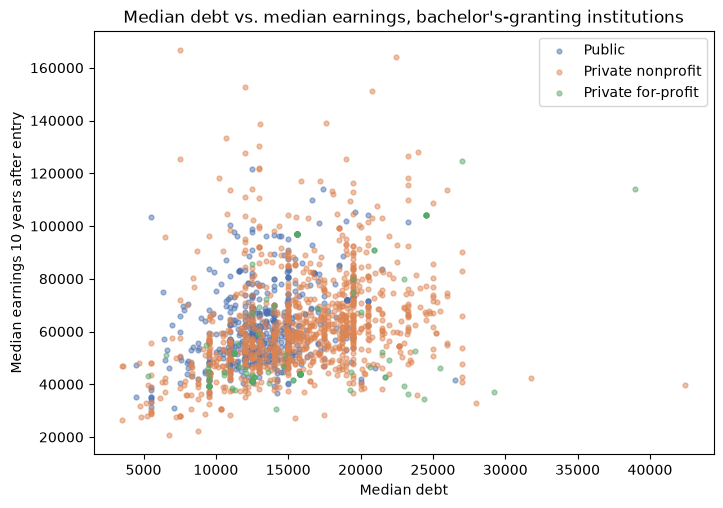

In [ ]:
colors = {"Public": "#4C72B0", "Private nonprofit": "#DD8452", "Private for-profit": "#55A868"}
plt.figure(figsize=(8, 5.5))
for group in group_names:
    group_data = complete[complete["CONTROL_LABEL"] == group]
    plt.scatter(group_data["DEBT_MDN"], group_data["MD_EARN_WNE_P10"],
                s=12, alpha=0.5, color=colors[group], label=group)
plt.xlabel("Median debt")
plt.ylabel("Median earnings 10 years after entry")
plt.title("Median debt vs. median earnings, bachelor's-granting institutions")
plt.legend()
plt.show()